In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, glob, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

DATA_DIR = "/content/drive/MyDrive/XPQRS"
OUTPUT_DIR = "/content/drive/MyDrive/XPQRS/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
EPOCHS = 40

# ---- Final configuration ----
FINAL_FILTERS = (32, 64, 128)
FINAL_KERNELS = (3, 3, 3)

RUN_CV = False     # True = also run 5-fold validation accuracy (~20 min on GPU)

COMPOUND_CLASSES = {
    "Flicker_with_Sag", "Flicker_with_Swell", "Harmonics_with_Sag",
    "Harmonics_with_Swell", "Sag_with_Harmonics", "Sag_with_Oscillatory_Transient",
    "Swell_with_Harmonics", "Swell_with_Oscillatory_Transient",
}

def set_seed(s=RANDOM_STATE):
    np.random.seed(s); random.seed(s); tf.random.set_seed(s)
set_seed()
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
signals, labels = [], []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    label = os.path.splitext(os.path.basename(path))[0]
    data = pd.read_csv(path, header=None)
    signals.append(data.values.astype(np.float32))
    labels.extend([label] * len(data))

X_raw = np.vstack(signals)
y = np.array(labels)
classes = sorted(np.unique(y))
encoder = LabelEncoder().fit(classes)
y_enc = encoder.transform(y)
is_compound = np.array([c in COMPOUND_CLASSES for c in classes])
N_SAMPLES = X_raw.shape[1]
X_all = X_raw.reshape(-1, N_SAMPLES, 1)

tv_path, te_path = f"{OUTPUT_DIR}/trainval_idx.npy", f"{OUTPUT_DIR}/test_idx.npy"
if os.path.exists(tv_path) and os.path.exists(te_path):
    trainval_idx, test_idx = np.load(tv_path), np.load(te_path)
    print("Loaded saved split")
else:
    trainval_idx, test_idx = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                              random_state=RANDOM_STATE, stratify=y)
    np.save(tv_path, trainval_idx); np.save(te_path, test_idx)
    print("Recreated the same 80/20 split and saved it")
assert len(set(trainval_idx) & set(test_idx)) == 0
print(f"{len(classes)} classes | train+validation pool: {len(trainval_idx)} | unseen test set: {len(test_idx)}")

Recreated the same 80/20 split and saved it
17 classes | train+validation pool: 13600 | unseen test set: 3400


In [4]:
def build_model(n_classes, n_samples, filters=FINAL_FILTERS, kernel_sizes=FINAL_KERNELS):
    x_in = layers.Input(shape=(n_samples, 1))
    x = x_in
    for i in range(3):
        x = layers.Conv1D(filters[i], kernel_size=kernel_sizes[i], activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        if i < 2:
            x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = models.Model(x_in, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]

build_model(len(classes), N_SAMPLES).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 100, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 25, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,297 (161.32 KB)

 Trainable params: 40,849 (159.57 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/40
362/362 - 13s - 35ms/step - accuracy: 0.4338 - loss: 1.7227 - val_accuracy: 0.1172 - val_loss: 4.7938 - learning_rate: 5.0000e-04
Epoch 2/40
362/362 - 2s - 5ms/step - accuracy: 0.6370 - loss: 1.0408 - val_accuracy: 0.4039 - val_loss: 1.6190 - learning_rate: 5.0000e-04
Epoch 3/40
362/362 - 1s - 4ms/step - accuracy: 0.7072 - loss: 0.8343 - val_accuracy: 0.7598 - val_loss: 0.6151 - learning_rate: 5.0000e-04
Epoch 4/40
362/362 - 2s - 4ms/step - accuracy: 0.7416 - loss: 0.7277 - val_accuracy: 0.7833 - val_loss: 0.6131 - learning_rate: 5.0000e-04
Epoch 5/40
362/362 - 1s - 4ms/step - accuracy: 0.7735 - loss: 0.6436 - val_accuracy: 0.7995 - val_loss: 0.5267 - learning_rate: 5.0000e-04
Epoch 6/40
362/362 - 1s - 4ms/step - accuracy: 0.7939 - loss: 0.5878 - val_accuracy: 0.7882 - val_loss: 0.5830 - learning_rate: 5.0000e-04
Epoch 7/40
362/362 - 1s - 4ms/step - accuracy: 0.8193 - loss: 0.5403 - val_accuracy: 0.8118 - val_loss: 0.4990 - learning_rate: 5.0000e-04
Epoch 8/40
362/362 - 1s -

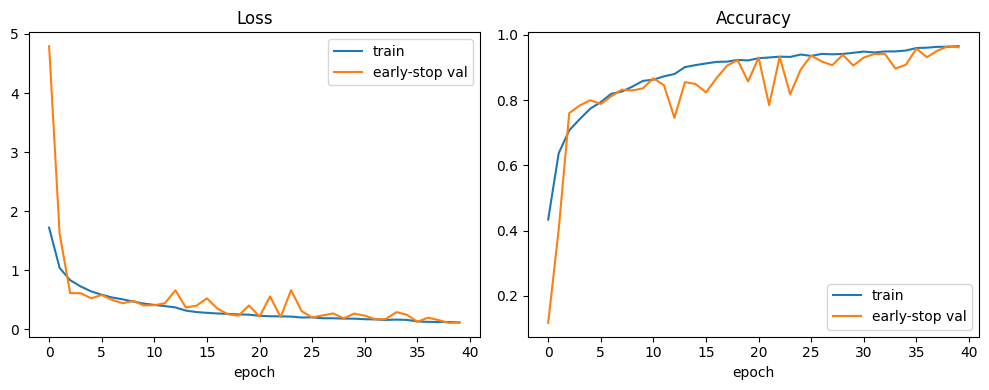

In [5]:
fit_idx, es_idx = train_test_split(trainval_idx, test_size=0.15, random_state=RANDOM_STATE,
                                   stratify=y[trainval_idx])   # early stopping only; test set not involved
tf.keras.backend.clear_session(); set_seed()
final_model = build_model(len(classes), N_SAMPLES)
t0 = time.time()
history = final_model.fit(X_all[fit_idx], y_enc[fit_idx],
                          validation_data=(X_all[es_idx], y_enc[es_idx]),
                          epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=2)
print(f"Trained in {time.time()-t0:.0f}s, {len(history.history['loss'])} epochs")
final_model.save(f"{OUTPUT_DIR}/final_model_k333_f32_64_128.keras")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="early-stop val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(history.history["accuracy"], label="train"); plt.plot(history.history["val_accuracy"], label="early-stop val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/final_training_curves.png", dpi=150); plt.show()

FINAL TEST ACCURACY (unseen 20%, 3400 signals): 96.12%
For reference, the earlier model (kernels 5-5-3) scored 96.35% on this same test set.

Test F1  single disturbances: 0.9645   compound: 0.9583

                                  precision    recall  f1-score   support

                         Flicker     0.9751    0.9800    0.9776       200
                Flicker_with_Sag     0.9893    0.9250    0.9561       200
              Flicker_with_Swell     0.9899    0.9800    0.9849       200
                       Harmonics     0.9950    1.0000    0.9975       200
              Harmonics_with_Sag     0.9798    0.9700    0.9749       200
            Harmonics_with_Swell     0.9949    0.9850    0.9899       200
                    Interruption     0.9851    0.9950    0.9900       200
                           Notch     0.9895    0.9400    0.9641       200
           Oscillatory_Transient     0.8702    0.9050    0.8873       200
                 Pure_Sinusoidal     0.9852    1.0000    0.9

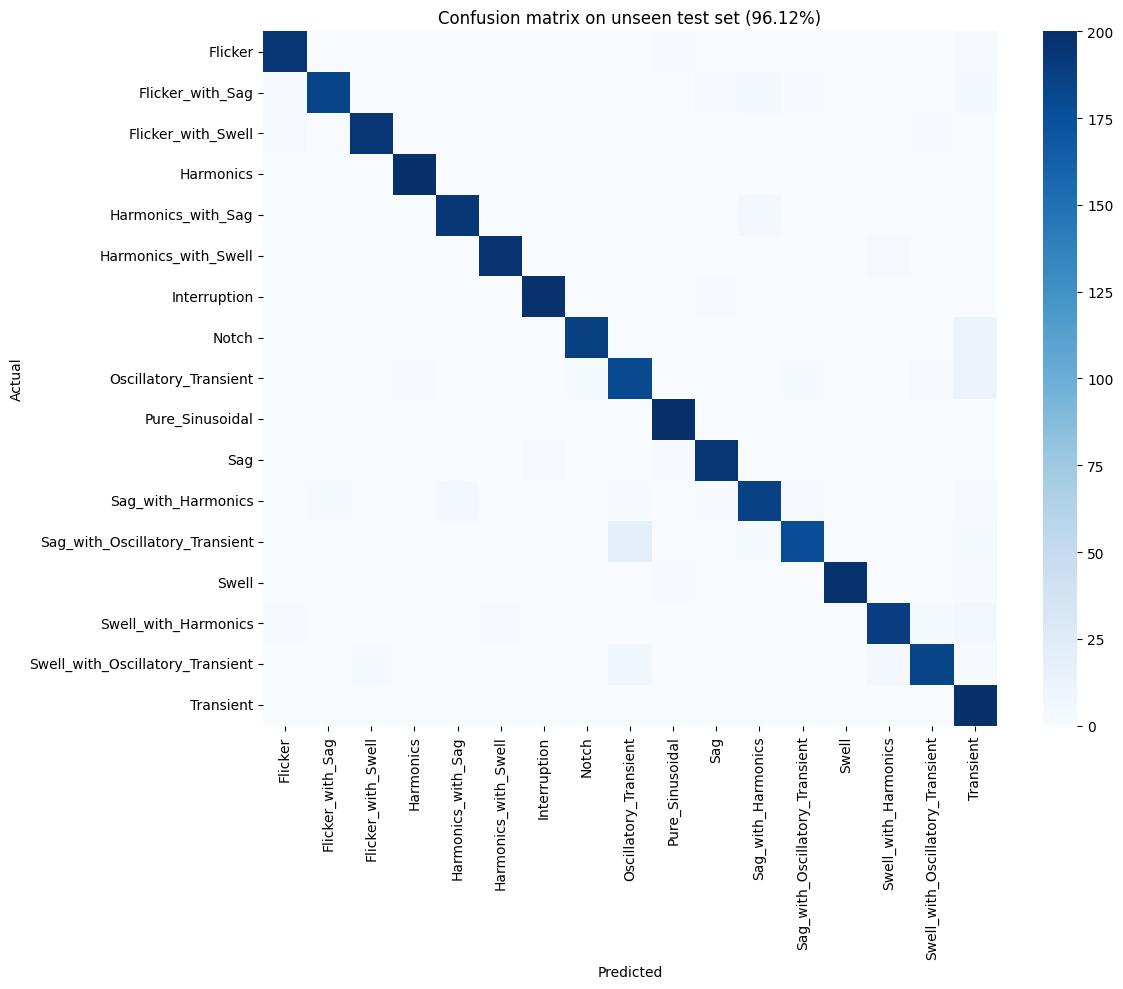

In [6]:
probs = final_model.predict(X_all[test_idx], verbose=0)
test_pred = probs.argmax(axis=1)
test_acc = accuracy_score(y_enc[test_idx], test_pred) * 100
print(f"FINAL TEST ACCURACY (unseen 20%, {len(test_idx)} signals): {test_acc:.2f}%")
print("For reference, the earlier model (kernels 5-5-3) scored 96.35% on this same test set.\n")

f1_test = f1_score(y_enc[test_idx], test_pred, labels=range(len(classes)), average=None, zero_division=0)
print(f"Test F1  single disturbances: {f1_test[~is_compound].mean():.4f}   compound: {f1_test[is_compound].mean():.4f}\n")
report = classification_report(y_enc[test_idx], test_pred, target_names=classes, digits=4, zero_division=0)
print(report)
open(f"{OUTPUT_DIR}/final_test_classification_report.txt", "w").write(f"Test accuracy: {test_acc:.2f}%\n\n{report}")

cm = confusion_matrix(y_enc[test_idx], test_pred, labels=range(len(classes)))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.title(f"Confusion matrix on unseen test set ({test_acc:.2f}%)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=90)
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/final_test_confusion.png", dpi=150); plt.show()

Overall accuracy: 96.12%
Single disturbances: 97.67%   Compound: 94.38%
Mean confidence  correct: 0.972   wrong: 0.718

Accuracy per class (lowest first):
true_class
Sag_with_Oscillatory_Transient       89.0
Oscillatory_Transient                90.5
Flicker_with_Sag                     92.5
Swell_with_Oscillatory_Transient     92.5
Sag_with_Harmonics                   93.0
Notch                                94.0
Swell_with_Harmonics                 94.5
Harmonics_with_Sag                   97.0
Flicker                              98.0
Sag                                  98.0
Flicker_with_Swell                   98.0
Harmonics_with_Swell                 98.5
Swell                                99.0
Interruption                         99.5
Harmonics                           100.0
Pure_Sinusoidal                     100.0
Transient                           100.0

Most common mistakes (true -> predicted):
true_class                        predicted_class      
Sag_with_Oscillatory_

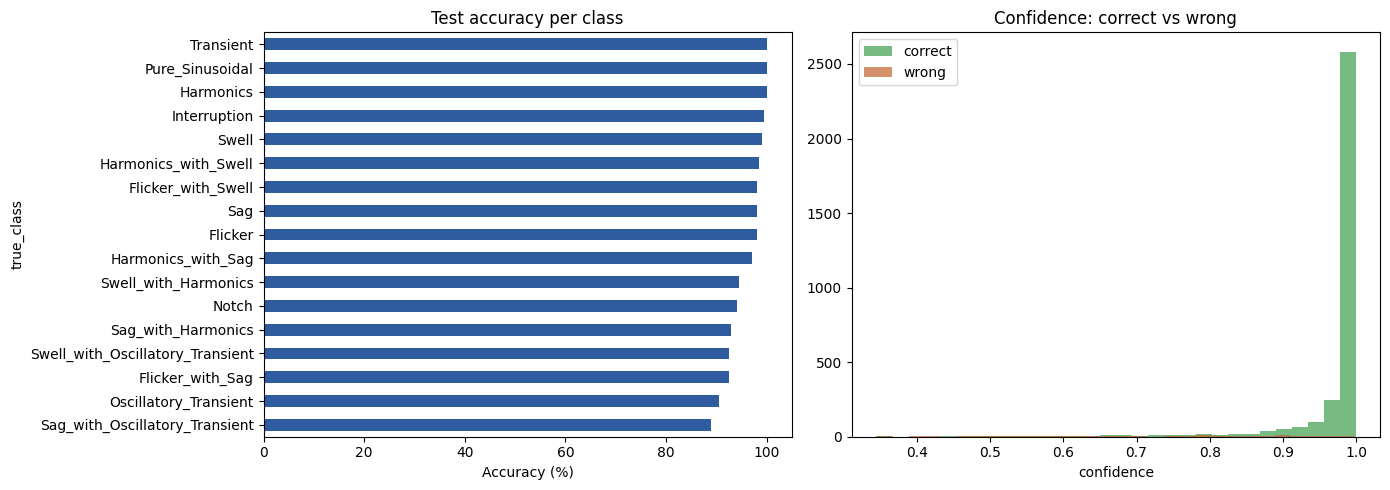

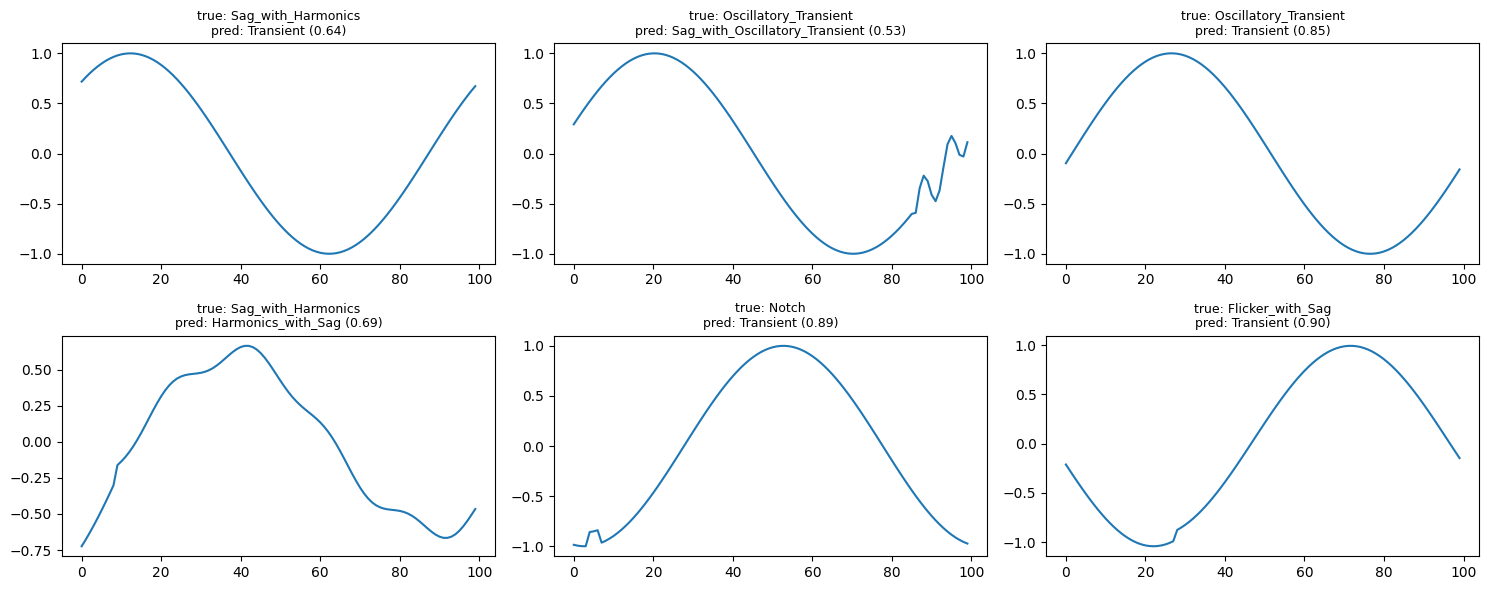

In [7]:
pred_df = pd.DataFrame({
    "signal_index": test_idx,
    "true_class": y[test_idx],
    "predicted_class": encoder.inverse_transform(test_pred),
    "confidence": probs.max(axis=1),
})
pred_df["correct"] = pred_df["true_class"] == pred_df["predicted_class"]
pred_df["is_compound"] = pred_df["true_class"].isin(COMPOUND_CLASSES)
pred_df.to_csv(f"{OUTPUT_DIR}/final_test_predictions.csv", index=False)

print(f"Overall accuracy: {pred_df['correct'].mean()*100:.2f}%")
print(f"Single disturbances: {pred_df[~pred_df.is_compound]['correct'].mean()*100:.2f}%   "
      f"Compound: {pred_df[pred_df.is_compound]['correct'].mean()*100:.2f}%")
print(f"Mean confidence  correct: {pred_df[pred_df.correct]['confidence'].mean():.3f}   "
      f"wrong: {pred_df[~pred_df.correct]['confidence'].mean():.3f}")

per_class = pred_df.groupby("true_class")["correct"].mean().mul(100).sort_values()
print("\nAccuracy per class (lowest first):"); print(per_class.round(2).to_string())

wrong = pred_df[~pred_df.correct]
print("\nMost common mistakes (true -> predicted):")
print(wrong.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False).head(10).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
per_class.plot.barh(ax=ax[0], color="#2F5C9E"); ax[0].set_xlabel("Accuracy (%)"); ax[0].set_title("Test accuracy per class")
ax[1].hist(pred_df[pred_df.correct]["confidence"], bins=30, alpha=0.7, label="correct", color="#3F9E4D")
ax[1].hist(wrong["confidence"], bins=30, alpha=0.7, label="wrong", color="#C4622D")
ax[1].set_xlabel("confidence"); ax[1].set_title("Confidence: correct vs wrong"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/final_prediction_analysis.png", dpi=150); plt.show()

n = min(6, len(wrong))
if n:
    ex = wrong.sample(n, random_state=RANDOM_STATE)
    fig, axes = plt.subplots(2, 3, figsize=(15, 6))
    for a, (_, r) in zip(axes.ravel(), ex.iterrows()):
        a.plot(X_raw[r.signal_index])
        a.set_title(f"true: {r.true_class}\npred: {r.predicted_class} ({r.confidence:.2f})", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/final_wrong_prediction_examples.png", dpi=150); plt.show()

In [8]:
if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_accs = []
    for k, (tr, va) in enumerate(skf.split(trainval_idx, y[trainval_idx]), start=1):
        tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
        f_idx, e_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y[tr_idx])
        tf.keras.backend.clear_session(); set_seed()
        m = build_model(len(classes), N_SAMPLES)
        m.fit(X_all[f_idx], y_enc[f_idx], validation_data=(X_all[e_idx], y_enc[e_idx]),
              epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
        acc = accuracy_score(y_enc[va_idx], np.argmax(m.predict(X_all[va_idx], verbose=0), axis=1)) * 100
        cv_accs.append(acc); print(f"Fold {k}/5 validation accuracy: {acc:.2f}%")
    cv_accs = np.array(cv_accs)
    print(f"\nMean validation accuracy: {cv_accs.mean():.2f}%   Std: {cv_accs.std():.2f}%")
    pd.DataFrame({"fold": range(1, 6), "validation_accuracy": cv_accs}).to_csv(f"{OUTPUT_DIR}/final_cv_validation.csv", index=False)
else:
    print("RUN_CV is False, skipped.")

RUN_CV is False, skipped.


In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_accs = []
for k, (tr, va) in enumerate(skf.split(trainval_idx, y[trainval_idx]), start=1):
    tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
    f_idx, e_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y[tr_idx])
    tf.keras.backend.clear_session(); set_seed()
    m = build_model(len(classes), N_SAMPLES)
    m.fit(X_all[f_idx], y_enc[f_idx], validation_data=(X_all[e_idx], y_enc[e_idx]),
          epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
    acc = accuracy_score(y_enc[va_idx], np.argmax(m.predict(X_all[va_idx], verbose=0), axis=1)) * 100
    cv_accs.append(acc)
    print(f"Fold {k}/5 validation accuracy: {acc:.2f}%")

cv_accs = np.array(cv_accs)
print(f"\nMean validation accuracy: {cv_accs.mean():.2f}%   Std: {cv_accs.std():.2f}%")
pd.DataFrame({"fold": range(1, 6), "validation_accuracy": cv_accs}).to_csv(
    f"{OUTPUT_DIR}/final_cv_validation.csv", index=False)

Fold 1/5 validation accuracy: 96.18%
Fold 2/5 validation accuracy: 96.62%
Fold 3/5 validation accuracy: 95.37%
Fold 4/5 validation accuracy: 94.93%
Fold 5/5 validation accuracy: 95.15%

Mean validation accuracy: 95.65%   Std: 0.64%
